# Chapter 4

Python version of the R code for Chapter 4 of *In All Likelihood* (Pawitan, 2001).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize, special

from helpers import DATA, li, approx, qqnorm, qqline

## Example 4.1 (`EX4-1.R`)

[0.50050703 0.9637903 ]


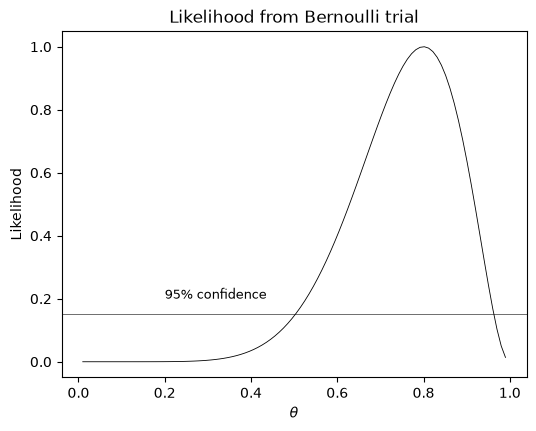

In [2]:
x, n = 8, 10

theta = np.linspace(0.01, .99, 100)
like = stats.binom.pmf(8, 10, theta)
like1 = like / like.max()
print(li(theta, like1, np.exp(-1.92)))

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(theta, like1, "k-", lw=0.6)
ax.axhline(.15, color="k", lw=0.4)
ax.text(.2, .2, "95% confidence", fontsize=9)
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Likelihood")
ax.set_title("Likelihood from Bernoulli trial")
plt.show()

## Example 4.2 (`EX4-2.R`)

In [3]:
k = np.arange(0, 13)
nk = np.array([3, 24, 104, 286, 670, 1033, 1343, 1112, 829, 478, 181, 45, 7])
N = nk.sum()
pk = nk / N

th = np.sum(k * pk) / 12
ihat = np.sum(k * nk) / th ** 2 + np.sum((12 - k) * nk) / (1 - th) ** 2
se = np.sqrt(1 / ihat)
print("est=", th, "se=", se)

est= 0.5192150449713818 se= 0.0018444216651607962


## Example 4.3 (`EX4-3.R`)

In [4]:
k = np.arange(0, 13)
nk = np.array([3, 24, 104, 286, 670, 1033, 1343, 1112, 829, 478, 181, 45, 7])
N = nk.sum()
pk = nk / N
th = np.sum(k * pk) / 12

# observed variance vs binomial variance:
# s2 = np.sum(pk * (k - 12 * th) ** 2); print(s2, 12 * th * (1 - th))

# residuals:
est = N * stats.binom.pmf(k, 12, th)  # expected frequencies

chi2 = np.sum((nk - est) ** 2 / est)
print(chi2, 1 - stats.norm.cdf(chi2, 11))

res = (nk - est) / np.sqrt(est)
print(pd.DataFrame({"Obs": nk, "Exp": np.round(est), "Residual": np.round(res, 1)}))

110.50495839413291 0.0
     Obs     Exp  Residual
0      3     1.0       2.1
1     24    12.0       3.4
2    104    72.0       3.8
3    286   258.0       1.7
4    670   628.0       1.7
5   1033  1085.0      -1.6
6   1343  1367.0      -0.7
7   1112  1266.0      -4.3
8    829   854.0      -0.9
9    478   410.0       3.4
10   181   133.0       4.2
11    45    26.0       3.7
12     7     2.0       3.0


## Example 4.4 (`EX4-4.R`)

theta-hat= 1.5040773967762742 ,  se= 1.1879019787470309


0.3723855901148279
95% CI for theta= [-0.54443637  4.52424251]
Likelihood of theta=0 0.025223570464514004
lower limit of 15% likelihood interval for theta= 0.93400539556346


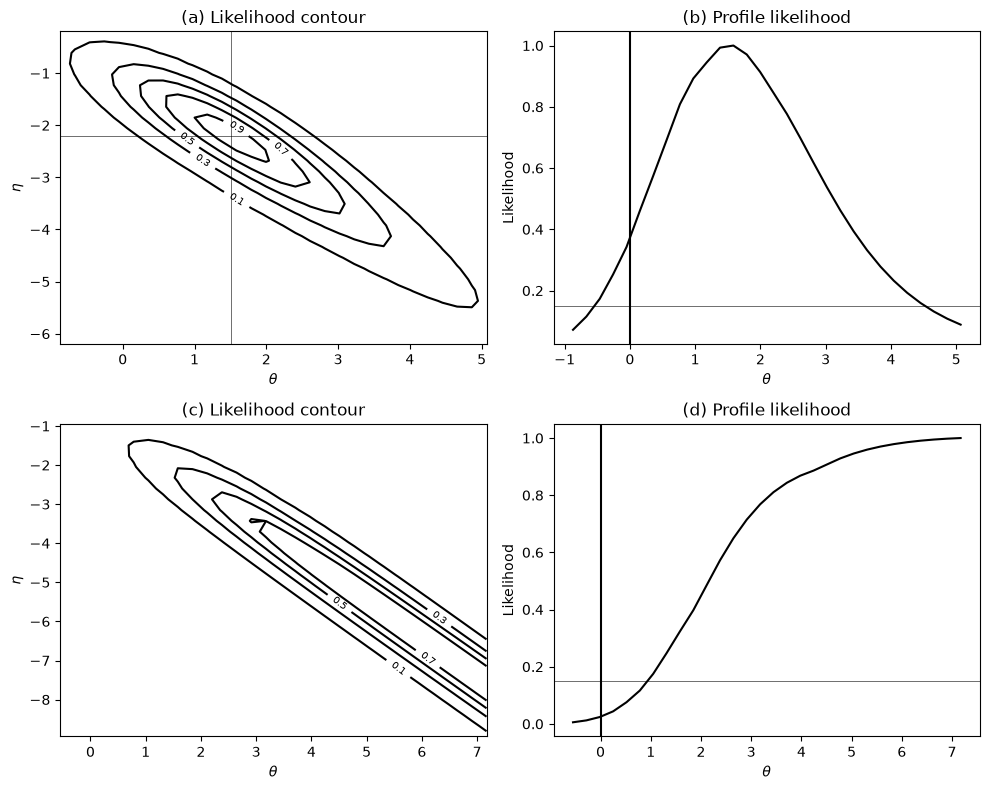

In [5]:
x, m = 5, 15
y, n = 1, 10

that = np.log(x / (m - x) * (n - y) / y)
se2 = 1 / x + 1 / (m - x) + 1 / y + 1 / (n - y)
se = np.sqrt(se2)

ehat = np.log(y / (n - y))
print("theta-hat=", that, ",  se=", se)

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.ravel()
th = np.linspace(that - 2 * se, that + 3 * se, 30)
et = np.linspace(ehat - 4, ehat + 2, 30)


def fun1(theta, eta):
    a = np.exp(theta + eta)
    b = np.exp(eta)
    return x * theta + (x + y) * eta - m * np.log(1 + a) - n * np.log(1 + b)


ll = fun1(th[:, None], et[None, :])
like = np.exp(ll - ll.max())
ax = axes[0]
cs = ax.contour(th, et, like.T, levels=[.1, .3, .5, .7, .9], colors="k")
ax.clabel(cs, fontsize=7)
ax.axvline(that, color="k", lw=0.4)
ax.axhline(ehat, color="k", lw=0.4)
ax.set_xlabel(r"$\theta$")
ax.set_ylabel(r"$\eta$")
ax.set_title("(a) Likelihood contour")

lik1 = like.max(axis=1)
ax = axes[1]
ax.plot(th, lik1, "k-")
ax.axhline(.15, color="k", lw=0.4)
ax.axvline(0, color="k")
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Likelihood")
ax.set_title("(b) Profile likelihood")

# getting likelihood of H0
a = approx(th, lik1, 0)
print(a)

# getting likelihood interval
a = li(th, lik1, 0.15)
print("95% CI for theta=", a)

# ................... more extreme table
x, m = 6, 15
y, n = 0, 10

y = 0.5  # only to get estimates for plotting purpose
that = np.log(x / (m - x) * (n - y) / y)
se2 = 1 / x + 1 / (m - x) + 1 / y + 1 / (n - y)
se = np.sqrt(se2)

ehat = np.log(y / (n - y))

th = np.linspace(that - 2 * se, that + 3 * se, 30)
et = np.linspace(ehat - 6, ehat + 2, 30)

y = 0  # the actual value of y
ll = fun1(th[:, None], et[None, :])
like = np.exp(ll - ll.max())
ax = axes[2]
cs = ax.contour(th, et, like.T, levels=[.1, .3, .5, .7], colors="k")
ax.clabel(cs, fontsize=7)
ax.set_xlabel(r"$\theta$")
ax.set_ylabel(r"$\eta$")
ax.set_title("(c) Likelihood contour")

lik1 = like.max(axis=1)
ax = axes[3]
ax.plot(th, lik1, "k-")
ax.axhline(.15, color="k", lw=0.4)
ax.axvline(0, color="k")
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Likelihood")
ax.set_title("(d) Profile likelihood")

# likelihood of theta=0
a = approx(th, lik1, 0)
print("Likelihood of theta=0", a)

# lower bound
a = li(th, lik1, 0.15)
print("lower limit of 15% likelihood interval for theta=", a[0])

fig.tight_layout()
plt.show()

## Example 4.5 (`EX4-5.R`)

Poisson data.

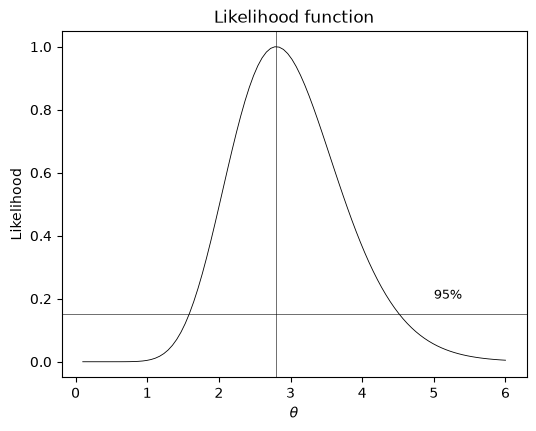

mean= 2.8
se  = 0.7483314773547882
95% CI= [1.58302292 4.52142193]


In [6]:
x = np.array([3, 2, 5, 0, 4])
n = len(x)

mu = np.linspace(.1, 6, 100)
ll = -n * mu + x.sum() * np.log(mu)
like = np.exp(ll - ll.max())

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(mu, like, "k-", lw=0.6)
ax.axvline(x.mean(), color="k", lw=0.4)
ax.axhline(.15, color="k", lw=0.4)
ax.text(5, .2, "95%", fontsize=9)
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Likelihood")
ax.set_title("Likelihood function")
plt.show()

print("mean=", x.mean())
print("se  =", np.sqrt(x.mean() / n))
print("95% CI=", li(mu, like, .15))

## Figure 4.5 (`FIG4-5.R`)

Section 4.6.

mle=  1.1176470588235294 ,  95% CI= [0.909955   1.37375569]
mle=  1.75 ,  95% CI= [1.02362589 3.07335682]
mle=  1.35 ,  95% CI= [0.90106268 2.03884988]
mle=  0.8666666666666667 ,  95% CI= [0.62039302 1.2066178 ]
mle=  0.2 ,  95% CI= [0.02784488 0.75462149]


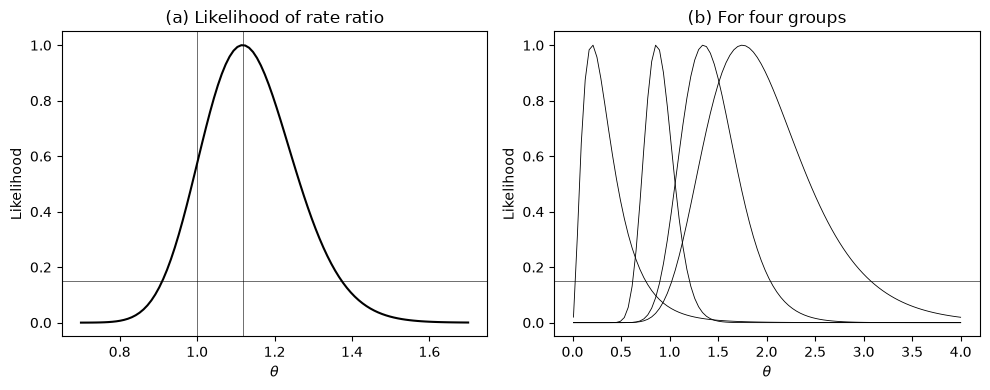

In [7]:
x = 170
y = 190

theta = np.linspace(.7, 1.7, 100)
ll = y * np.log(theta) - (x + y) * np.log(1 + theta)
like = np.exp(ll - ll.max())

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = axes[0]
ax.plot(theta, like, "k-")
mle = y / x
ax.axvline(mle, color="k", lw=0.4)
ax.axvline(1, color="k", lw=0.4)
ax.axhline(.15, color="k", lw=0.4)
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Likelihood")
ax.set_title("(a) Likelihood of rate ratio")

print("mle= ", mle, ",  95% CI=", li(theta, like, 0.15))

xx = [20, 40, 75, 10]
yy = [35, 54, 65, 2]
theta = np.linspace(.01, 4, 100)
ax = axes[1]
ax.axhline(.15, color="k", lw=0.4)

for x, y in zip(xx, yy):
    ll = y * np.log(theta) - (x + y) * np.log(1 + theta)
    like = np.exp(ll - ll.max())
    ax.plot(theta, like, "k-", lw=0.6)
    mle = y / x
    print("mle= ", mle, ",  95% CI=", li(theta, like, 0.15))

ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Likelihood")
ax.set_title("(b) For four groups")
fig.tight_layout()
plt.show()

## Example 4.6 (`EX4-6.R`)

mle = 0.8421052631578947 ,  95% CI= [0.65331883 1.06428624]
mle = 0.6933333333333334 ,  95% CI= [0.52249479 0.89795495]
note: 0.53<theta<0.96 in the book is wrong. Should be 0.53<theta<0.90.


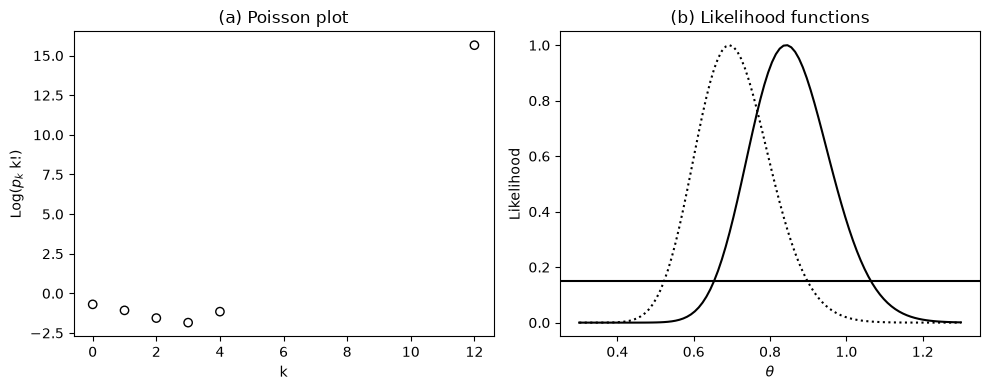

In [8]:
k = np.array([0, 1, 2, 3, 4, 12])
nk = np.array([38, 26, 8, 2, 1, 1])

kk = special.factorial(k)
pk = nk / nk.sum()
yk = np.log(pk * kk)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = axes[0]
ax.scatter(k, yk, facecolors="none", edgecolors="k")
ax.set_xlabel("k")
ax.set_ylabel(r"Log($p_k$ k!)")
ax.set_title("(a) Poisson plot")

mu = np.linspace(.3, 1.3, 100)
ll = -mu * nk.sum() + np.log(mu) * np.sum(k * nk)
like = np.exp(ll - ll.max())

mle = np.sum(k * nk) / nk.sum()
a = li(mu, like, 0.15)
print("mle =", mle, ",  95% CI=", a)

ax = axes[1]
ax.plot(mu, like, "k-")

# .................     excluding the month with k=12

k = np.array([0, 1, 2, 3, 4])
nk = np.array([38, 26, 8, 2, 1])

ll = -mu * nk.sum() + np.log(mu) * np.sum(k * nk)
like = np.exp(ll - ll.max())

ax.plot(mu, like, "k:", lw=1.5)
ax.axhline(.15, color="k")

mle = np.sum(k * nk) / nk.sum()
a = li(mu, like, 0.15)
print("mle =", mle, ",  95% CI=", a)
print("note: 0.53<theta<0.96 in the book is wrong. Should be 0.53<theta<0.90.")

ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Likelihood")
ax.set_title("(b) Likelihood functions")
fig.tight_layout()
plt.show()

## Figure 4.6 (`FIG4-6.R`)

Section 4.7.

95% CI= [0.47146353 0.7148497 ]
95% CI= [0.93144248 1.58638072]


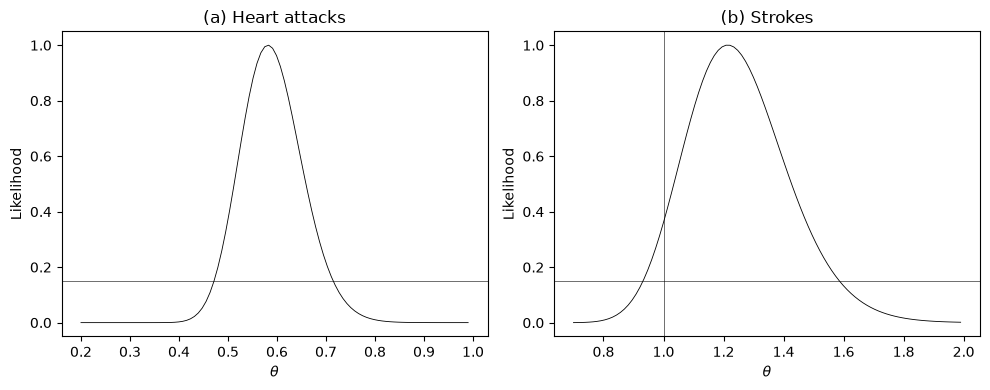

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# ..................... heart attacks
theta = np.linspace(0.2, .99, 100)
x = 139
y = 239

ll = x * np.log(theta / (theta + 1)) - y * np.log(theta + 1)
like = np.exp(ll - ll.max())

ax = axes[0]
ax.plot(theta, like, "k-", lw=0.6)
ax.axhline(.15, color="k", lw=0.4)
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Likelihood")
ax.set_title("(a) Heart attacks")
print("95% CI=", li(theta, like, 0.15))

# ..................... strokes
theta = np.linspace(0.7, 1.99, 100)
x = 119
y = 98

ll = x * np.log(theta / (theta + 1)) - y * np.log(theta + 1)
like = np.exp(ll - ll.max())

ax = axes[1]
ax.plot(theta, like, "k-", lw=0.6)
ax.axhline(.15, color="k", lw=0.4)
ax.axvline(1, color="k", lw=0.4)
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Likelihood")
ax.set_title("(b) Strokes")
print("95% CI=", li(theta, like, 0.15))

fig.tight_layout()
plt.show()

## Example 4.7 (`EX4-7.R`)

In [10]:
x = np.array([447, 132, 42, 21, 3, 2])
kk = np.arange(0, 5)
n = x.sum()

# Poisson fit
lam = np.sum(x * np.arange(0, 6)) / n
print("lambda-hat = ", lam)
phat = stats.poisson.pmf(np.arange(0, 6), lam)
fhat = n * phat
print(pd.DataFrame({"Obs": x, "E-Pois": np.round(fhat, 1)}))
chi2 = np.sum((x - fhat) ** 2 / fhat)
print("Chi2 goodness-of-fit = ", chi2)

lambda-hat =  0.4652241112828439
   Obs  E-Pois
0  447   406.3
1  132   189.0
2   42    44.0
3   21     6.8
4    3     0.8
5    2     0.1
Chi2 goodness-of-fit =  107.2855610680369


## Example 4.7 continued (`EX4-7C.R`)

Solving the Greenwood-Yule data using the negative binomial model.

In [11]:
x = np.array([447, 132, 42, 21, 3, 2])
kk = np.arange(0, 5)
n = x.sum()

# Poisson fit
lam = np.sum(x * np.arange(0, 6)) / n
print("lambda-hat = ", lam)
phat = stats.poisson.pmf(np.arange(0, 6), lam)
fhat_pois = n * phat


# negative binomial fit:
def dnbinom(x, n, p):
    return special.gamma(x + n) / special.gamma(n) / special.gamma(x + 1) * p ** n * (1 - p) ** x


def pnbinom(q, n, p):
    return stats.nbinom.cdf(q, n, p)


def fn(p):
    r, th = p
    if r <= 0 or not 0 < th < 1:
        return np.inf
    return -np.sum(x[:5] * np.log(dnbinom(kk, r, th))) - x[5] * np.log(1 - pnbinom(4, r, th))


a = optimize.minimize(fn, [.5, .5], method="Nelder-Mead")
est = a.x
print("alpha-hat=", est[0], " pi-hat=", est[1])

# fitted frequencies:
phat = np.append(dnbinom(kk, est[0], est[1]), 1 - pnbinom(4, est[0], est[1]))
fhat = n * phat

chi2 = np.sum((x - fhat) ** 2 / fhat)
print("Chi2 goodness-of-fit = ", chi2)

print(pd.DataFrame({"Obs": x, "E-Pois": np.round(fhat_pois, 1), "E-NegBin": np.round(fhat, 1)}))

lambda-hat =  0.4652241112828439
alpha-hat= 0.843905255801459  pi-hat= 0.6438246370340577
Chi2 goodness-of-fit =  3.6921025623518373
   Obs  E-Pois  E-NegBin
0  447   406.3     446.2
1  132   189.0     134.1
2   42    44.0      44.0
3   21     6.8      14.9
4    3     0.8       5.1
5    2     0.1       2.7


## Figure 4.7 (`FIG4-7.R`)

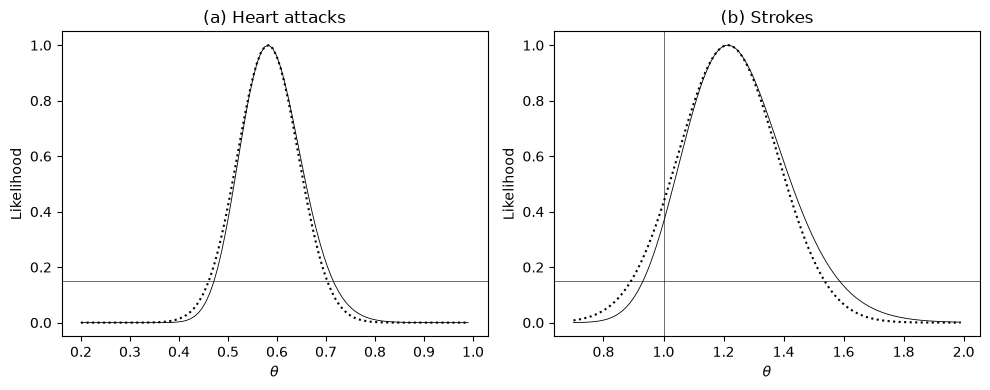

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# ...................... heart attacks
theta = np.linspace(0.2, .99, 100)
x = 139
y = 239

ll = x * np.log(theta / (theta + 1)) - y * np.log(theta + 1)
like = np.exp(ll - ll.max())

ax = axes[0]
ax.plot(theta, like, "k-", lw=0.6)
ax.axhline(.15, color="k", lw=0.4)
ax.set_title("(a) Heart attacks")

# normal approx
pihat = x / (x + y)
sd = np.sqrt(pihat / (1 - pihat) ** 3 / (x + y))
nlike = stats.norm.pdf(theta, x / y, sd)
nlike = nlike / nlike.max()
ax.plot(theta, nlike, "k:", lw=1.5)

# ...................... stroke
theta = np.linspace(0.7, 1.99, 1000)
x = 119
y = 98
llike = x * np.log(theta / (theta + 1)) - y * np.log(theta + 1)
like = np.exp(llike - llike.max())

ax = axes[1]
ax.plot(theta, like, "k-", lw=0.6)
ax.axhline(.15, color="k", lw=0.4)
ax.axvline(1, color="k", lw=0.4)
ax.set_title("(b) Strokes")

# normal approx
pihat = x / (x + y)
sd = np.sqrt(pihat / (1 - pihat) ** 3 / (x + y))
nlike = stats.norm.pdf(theta, x / y, sd)
nlike = nlike / nlike.max()
ax.plot(theta, nlike, "k:", lw=1.5)

for ax in axes:
    ax.set_xlabel(r"$\theta$")
    ax.set_ylabel("Likelihood")
fig.tight_layout()
plt.show()

## Figure 4.8 (`FIG4-8.R`)

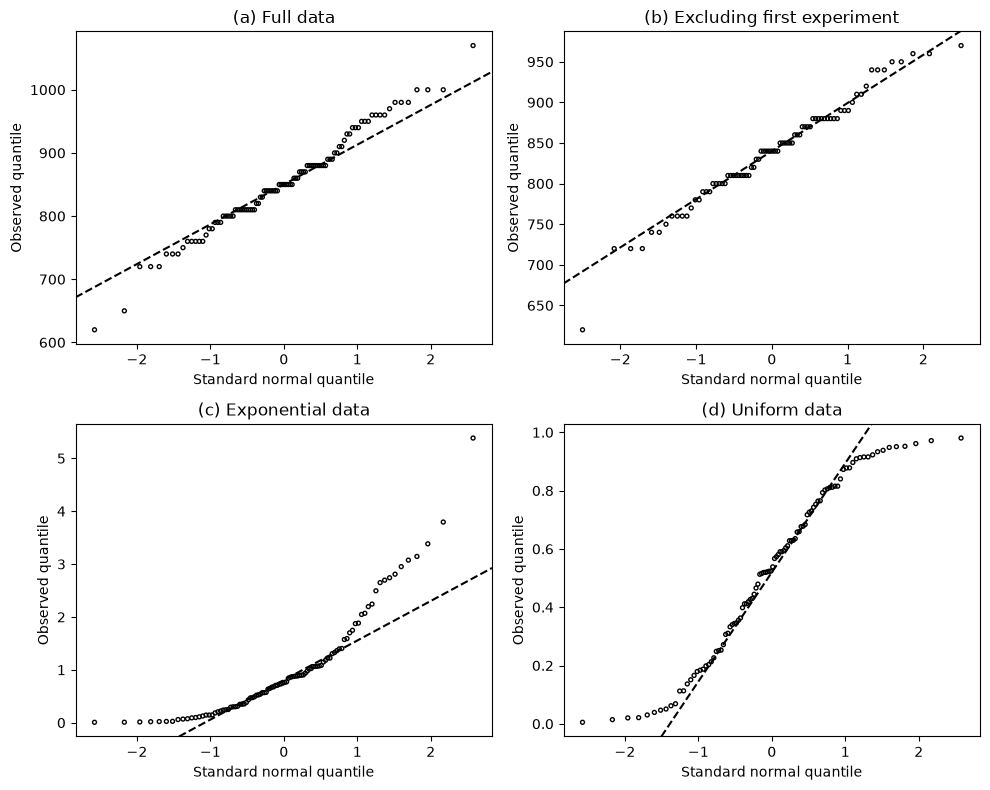

In [13]:
x = np.loadtxt(DATA / "michel.dat").ravel()


def qqplot(ax, x, title):
    q, s = qqnorm(x)
    ax.scatter(q, s, s=8, facecolors="none", edgecolors="k")
    qqline(ax, x, color="k", ls="--")
    ax.set_xlabel("Standard normal quantile")
    ax.set_ylabel("Observed quantile")
    ax.set_title(title)


fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.ravel()
qqplot(axes[0], x, "(a) Full data")
qqplot(axes[1], x[20:100], "(b) Excluding first experiment")

rng = np.random.default_rng(7)
x = rng.exponential(size=100)
qqplot(axes[2], x, "(c) Exponential data")

x = rng.uniform(size=100)
qqplot(axes[3], x, "(d) Uniform data")

fig.tight_layout()
plt.show()

## Example 4.9 (`EX4-9.R`)

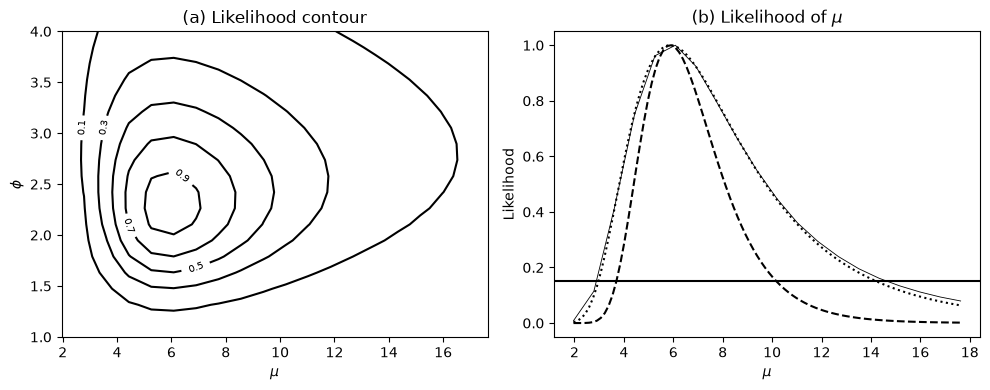

In [14]:
x = np.array([23.9, 27.3, 0.2, 3.6, 6.0, 0.9, 0.9,
              0.5, 0.2, 14.2, 6.2, 0.05, 3.9, 0.2, 0.1])
n = len(x)


def fun0(mu, phi):
    """Minus log-likelihood of the gamma model with mean mu and dispersion phi."""
    alpha = 1 / phi
    lam = 1 / (phi * mu)
    a = (-n * special.gammaln(alpha) + n * alpha * np.log(lam)
         + (alpha - 1) * np.sum(np.log(x)) - lam * np.sum(x))
    return -a


np_ = 20
mu = np.linspace(x.mean() / 3, x.mean() * 3, np_)
phi = np.linspace(1, 4, np_)

ll2 = fun0(mu[:, None], phi[None, :])
like2 = np.exp(ll2.min() - ll2)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = axes[0]
cs = ax.contour(mu, phi, like2.T, levels=[.1, .3, .5, .7, .9], colors="k")
ax.clabel(cs, fontsize=7)
ax.set_xlabel(r"$\mu$")
ax.set_ylabel(r"$\phi$")
ax.set_title("(a) Likelihood contour")

# profile likelihood
like = like2.max(axis=1)
ax = axes[1]
ax.plot(mu, like, "k-", lw=0.6)
ax.axhline(.15, color="k")
ax.set_xlabel(r"$\mu$")
ax.set_ylabel("Likelihood")
ax.set_title(r"(b) Likelihood of $\mu$")

np_ = 100
mu = np.linspace(x.mean() / 3, x.mean() * 3, np_)
ll = fun0(phi=2.35, mu=mu)
like = np.exp(ll.min() - ll)
ax.plot(mu, like, "k:", lw=1.5)

ll = fun0(phi=1, mu=mu)
like = np.exp(ll.min() - ll)
ax.plot(mu, like, "k--")

fig.tight_layout()
plt.show()

## Example 4.14 (`EX4-14.R`)

mean= 2.55 ,  var= 9.839473684210525 ,  ratio= 3.858617131062951
P-value= 0.0


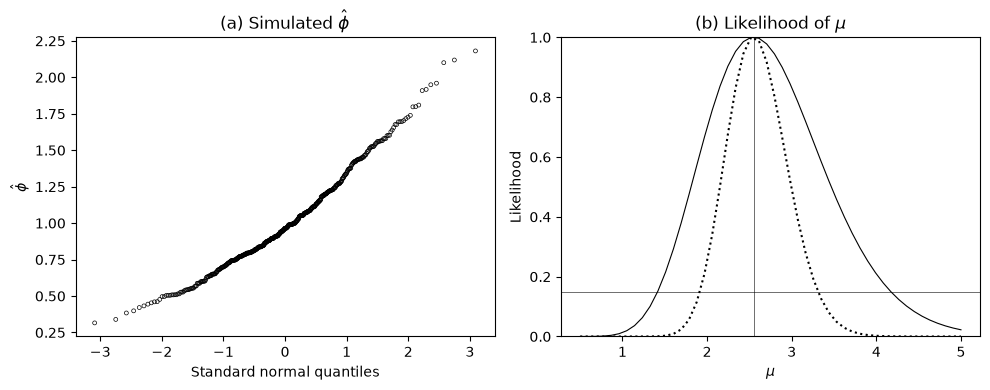

In [15]:
y = np.array([0, 10, 1, 1, 1, 2, 1, 4, 11,
              0, 5, 2, 5, 2, 0, 2, 0, 1, 3, 0])
n = len(y)

phi0 = np.var(y, ddof=1) / y.mean()
print("mean=", y.mean(), ",  var=", np.var(y, ddof=1), ",  ratio=", phi0)

# Monte Carlo test:
rng = np.random.default_rng()
a = rng.poisson(y.mean(), size=(500, n))  # simulated Poisson
amean = a.mean(axis=1)
avar = a.var(axis=1, ddof=1)
phi = avar / amean
print("P-value=", np.sum(phi > phi0) / 500)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = axes[0]
q, s = qqnorm(phi)
ax.scatter(q, s, s=8, facecolors="none", edgecolors="k", lw=0.5)
ax.set_xlabel("Standard normal quantiles")
ax.set_ylabel(r"$\hat\phi$")
ax.set_title(r"(a) Simulated $\hat\phi$")

mu = np.linspace(.5, 5, 50)
ll0 = np.log(mu) * y.sum() - n * mu
l0 = np.exp(ll0 - ll0.max())
ll = (np.log(mu) * y.sum() - n * mu) / phi0
l = np.exp(ll - ll.max())

ax = axes[1]
ax.plot(mu, l, "k-", lw=0.8)
ax.plot(mu, l0, "k:", lw=1.5)
ax.set_ylim(0, 1)
ax.axvline(y.mean(), color="k", lw=0.4)
ax.axhline(0.15, color="k", lw=0.4)
ax.set_xlabel(r"$\mu$")
ax.set_ylabel("Likelihood")
ax.set_title(r"(b) Likelihood of $\mu$")
fig.tight_layout()
plt.show()

## Example 4.16 (`EX4-16.R`)

Population of EU countries (in millions).

lambda-hat= 0.11630769230769232


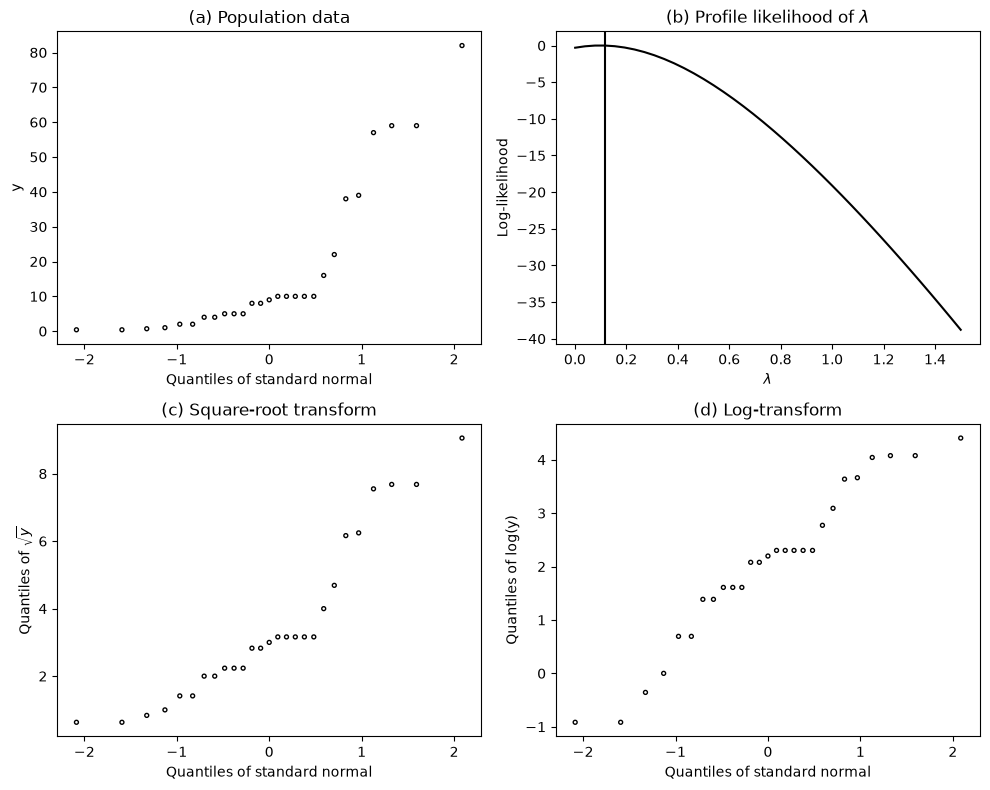

In [16]:
y = np.array([8, 10, 5, 5, 59, 82, 10, 57, 4, 0.4, 16, 10, 39, 9, 59,
              8, .7, 10, 1, 10, 4, 2, 0.4, 38, 22, 5, 2])
# y = y + 1    # much better normal transform

# Exercise 4.39: brain weight   # lhat=0.08
# y = np.array([0.4, 1.0, 1.9, 3.0, 5.5, 8.1, 12.1, 25.6, 50.0, 56.0,
#               70.0, 115.0, 115.0, 119.5, 154.5, 157.0, 175.0, 179.0,
#               180.0, 406.0, 419.0, 423.0, 440.0, 655.0, 680.0, 1320.0,
#               4603.0, 5712.0])

n = len(y)

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.ravel()

ax = axes[0]
q, s = qqnorm(y)
ax.scatter(q, s, s=8, facecolors="none", edgecolors="k")
ax.set_xlabel("Quantiles of standard normal")
ax.set_ylabel("y")
ax.set_title("(a) Population data")

nl = 40
lam = np.linspace(.001, 1.5, nl)
ll = []
for li_ in lam:
    yl = (y ** li_ - 1) / li_
    sl2 = np.var(yl)  # divisor n
    ll.append(-n / 2 * np.log(sl2) + (li_ - 1) * np.sum(np.log(y)))
ll = np.array(ll)
ll = ll - ll.max()

ax = axes[1]
ax.plot(lam, ll, "k-")
ax.set_xlabel(r"$\lambda$")
ax.set_ylabel("Log-likelihood")
ax.set_title(r"(b) Profile likelihood of $\lambda$")
lmax = lam[ll == ll.max()].max()
ax.axvline(lmax, color="k")
print("lambda-hat=", lmax)  # MLE of lambda

ax = axes[2]
q, s = qqnorm(np.sqrt(y))
ax.scatter(q, s, s=8, facecolors="none", edgecolors="k")
ax.set_xlabel("Quantiles of standard normal")
ax.set_ylabel(r"Quantiles of $\sqrt{y}$")
ax.set_title("(c) Square-root transform")

ax = axes[3]
q, s = qqnorm(np.log(y))
ax.scatter(q, s, s=8, facecolors="none", edgecolors="k")
ax.set_xlabel("Quantiles of standard normal")
ax.set_ylabel("Quantiles of log(y)")
ax.set_title("(d) Log-transform")

fig.tight_layout()
plt.show()

## Example 4.17 (`EX4-17.R`)

Heavy-tailed data example.

normal AIC= 189.73391301395233
Cauchy muhat = [3.68874167 2.21046214]
Cauchy AIC =  169.32305394218082
normal AIC= 439.5814649300519
Cauchy AIC= 456.29622502398684


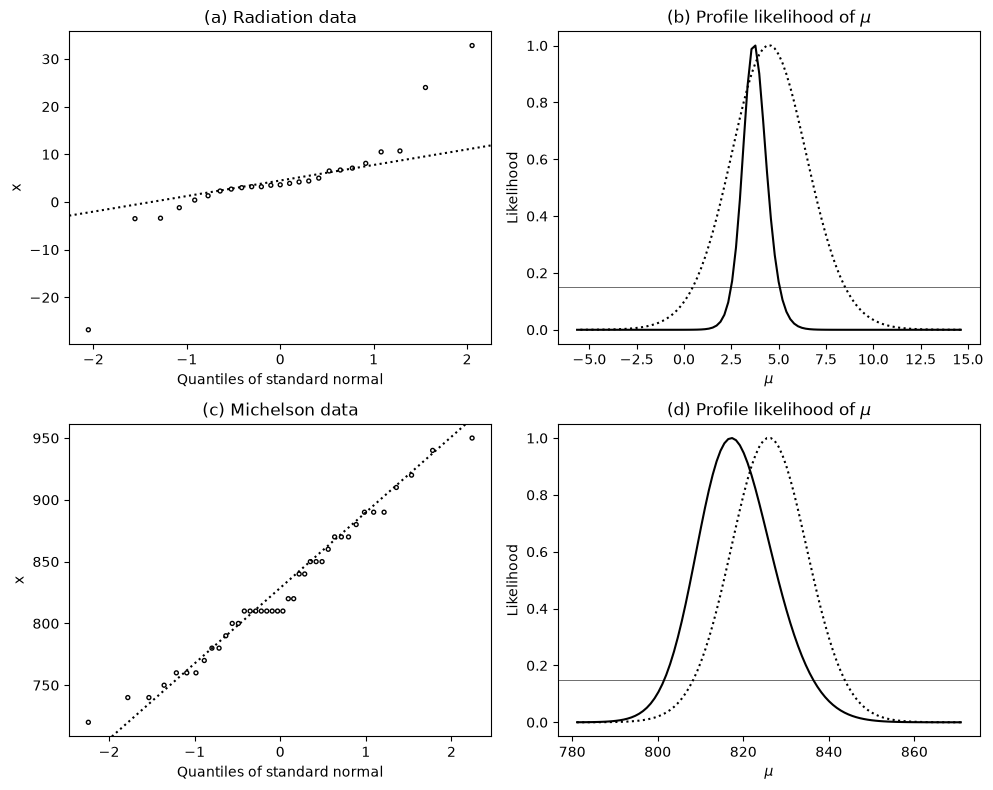

In [17]:
def cauchy_profile(x, mu):
    """Profile minus log-likelihood of mu under the Cauchy model."""
    out = []
    for mui in mu:
        def fun2(sigma):  # -loglike from cauchy
            return -np.sum(stats.cauchy.logpdf(x, mui, sigma))
        out.append(optimize.minimize_scalar(fun2, bounds=(1e-6, 1e4), method="bounded").fun)
    return np.array(out)


x = np.array([-26.8, -3.5, -3.4, -1.2, 0.4, 1.3, 2.3, 2.7,
              3.0, 3.2, 3.2, 3.5, 3.6, 3.9, 4.2, 4.4,
              5.0, 6.5, 6.7, 7.1, 8.1, 10.5, 10.7, 24.0, 32.8])
n = len(x)

s2 = np.var(x)  # divisor n
llmax = np.sum(np.log(stats.norm.pdf(x, x.mean(), np.sqrt(s2))))  # maximized likelihood
print("normal AIC=", -2 * llmax + 2 * 2)

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.ravel()

ax = axes[0]
q, s = qqnorm(x)
ax.scatter(q, s, s=8, facecolors="none", edgecolors="k")
qqline(ax, x, color="k", ls=":")
ax.set_xlabel("Quantiles of standard normal")
ax.set_ylabel("x")
ax.set_title("(a) Radiation data")

np_ = 100
xbar = x.mean()
sd = np.std(x, ddof=1)
mu = np.linspace(xbar + 5 * sd / np.sqrt(n), xbar - 5 * sd / np.sqrt(n), np_)
nsig = (np.abs(x[None, :] - mu[:, None]) ** 2).sum(axis=1)
p = 2
loglik = -n / p * np.log(nsig / n) - n / 2
lik1 = np.exp(loglik - loglik.max())

ax = axes[1]
ax.plot(mu, lik1, "k:", lw=1.5)


# cauchy likelihood:
def fun3(p):  # -loglike from cauchy
    mu, sigma = p
    if sigma <= 0:
        return np.inf
    return -np.sum(stats.cauchy.logpdf(x, mu, sigma))


a = optimize.minimize(fun3, [0.3, 1], method="Nelder-Mead")
print("Cauchy muhat =", a.x)
print("Cauchy AIC = ", 2 * a.fun + 4)

# profile from cauchy model
ll = cauchy_profile(x, mu)
ll = np.exp(ll.min() - ll)
ax.plot(mu, ll, "k-")
ax.axhline(.15, color="k", lw=0.4)
ax.set_xlabel(r"$\mu$")
ax.set_ylabel("Likelihood")
ax.set_title(r"(b) Profile likelihood of $\mu$")

# .................. more normal data

# speed of light data from Example 4.8
x = np.array([890, 810, 810, 820, 800, 770, 760, 740, 750, 760,
              910, 920, 890, 860, 880, 720, 840, 850, 850, 780,
              890, 840, 780, 810, 760, 810, 790, 810, 820, 850,
              870, 870, 810, 740, 810, 940, 950, 800, 810, 870], dtype=float)

# speed of light Michelson 1882, from Stigler 1977
# x = np.array([883, 816, 778, 796, 682, 711, 611, 599, 1051, 781, 578,
#               796, 774, 820, 772, 696, 573, 748, 748, 797, 851, 809, 723])

n = len(x)
s2 = np.var(x)
llmax = np.sum(np.log(stats.norm.pdf(x, x.mean(), np.sqrt(s2))))  # maximized likelihood
print("normal AIC=", -2 * llmax + 2 * 2)

ax = axes[2]
q, s = qqnorm(x)
ax.scatter(q, s, s=8, facecolors="none", edgecolors="k")
qqline(ax, x, color="k", ls=":")
ax.set_xlabel("Quantiles of standard normal")
ax.set_ylabel("x")
ax.set_title("(c) Michelson data")

xbar = x.mean()
sd = np.std(x, ddof=1)
mu = np.linspace(xbar + 5 * sd / np.sqrt(n), xbar - 5 * sd / np.sqrt(n), np_)
nsig = (np.abs(x[None, :] - mu[:, None]) ** 2).sum(axis=1)
p = 2
loglik = -n / p * np.log(nsig / n) - n / 2
lik1 = np.exp(loglik - loglik.max())

ax = axes[3]
ax.plot(mu, lik1, "k:", lw=1.5)

# profile from cauchy model
ll = cauchy_profile(x, mu)
print("Cauchy AIC=", 2 * ll.min() + 2 * 2)

ll = np.exp(ll.min() - ll)
ax.plot(mu, ll, "k-")
ax.axhline(.15, color="k", lw=0.4)
ax.set_xlabel(r"$\mu$")
ax.set_ylabel("Likelihood")
ax.set_title(r"(d) Profile likelihood of $\mu$")

fig.tight_layout()
plt.show()